# NB13: Registration QC

> **Local pipeline required.** This notebook inspects co-registration outputs and cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose
Quality control of the co-registration step (register_to_t1w.sh). Verify that
all modalities are correctly aligned in the fMRIPrep native T1w space.

## Interactive Inspection
```bash
# Full multi-modal overlay
bash scripts/freeview_all.sh --subject PAT16 --session preop

# Registration-specific QC
bash scripts/freeview_registration.sh --subject PAT16 --session preop
```

## QC Checklist
- [ ] DWI reference (b0) overlays correctly on T1w at cortical boundaries
- [ ] FA map follows white matter anatomy visible on T1w
- [ ] aparc+aseg labels match T1w anatomy
- [ ] Tractography streamlines follow white matter visible on T1w
- [ ] No systematic shift or rotation visible

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
REG_DIR = DERIV_ROOT / 'registered_t1w'
FMRIPREP_DIR = DERIV_ROOT / 'fmriprep'
SUBJECTS = ['PAT16']
SESSIONS = ['preop', 'postop']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Registered Output Inventory

In [2]:
expected = [
    'fa_space-T1w.nii.gz', 'md_space-T1w.nii.gz',
    'ad_space-T1w.nii.gz', 'rd_space-T1w.nii.gz',
    'wm_fod_norm_space-T1w.mif',
    'whole_brain_space-T1w.tck',
    'whole_brain_space-T1w_100k.tck',
    'whole_brain_space-T1w_100k.trk',
    'sift2_weights.txt',
    'aparc+aseg_space-T1w.nii.gz',
    'aseg_space-T1w.nii.gz',
    'brain_fs_space-T1w.nii.gz',
    'transforms/acpc_to_t1w_flirt.mat',
    'transforms/acpc_to_t1w_mrtrix.txt',
    'transforms/dwiref_in_T1w.nii.gz',
]

for sub in SUBJECTS:
    print(f'\n=== sub-{sub} ===')
    for ses in SESSIONS:
        out = REG_DIR / f'sub-{sub}' / f'ses-{ses}'
        print(f'  ses-{ses}:')
        if not out.exists():
            print('    Not yet run')
            continue
        for f in expected:
            fp = out / f
            if fp.exists():
                size = fp.stat().st_size / 1e6
                print(f'    [OK] {f:<40s} {size:>8.1f} MB')
            else:
                print(f'    [--] {f}')


=== sub-PAT16 ===
  ses-preop:
    [OK] fa_space-T1w.nii.gz                           6.0 MB
    [OK] md_space-T1w.nii.gz                           5.9 MB
    [OK] ad_space-T1w.nii.gz                           5.9 MB
    [OK] rd_space-T1w.nii.gz                           6.0 MB
    [OK] wm_fod_norm_space-T1w.mif                  1887.4 MB
    [OK] whole_brain_space-T1w.tck                  7693.7 MB
    [OK] whole_brain_space-T1w_100k.tck               92.3 MB
    [OK] whole_brain_space-T1w_100k.trk               91.5 MB
    [OK] sift2_weights.txt                           124.8 MB
    [OK] aparc+aseg_space-T1w.nii.gz                   0.5 MB
    [OK] aseg_space-T1w.nii.gz                         0.5 MB
    [OK] brain_fs_space-T1w.nii.gz                     1.2 MB
    [OK] transforms/acpc_to_t1w_flirt.mat              0.0 MB
    [OK] transforms/acpc_to_t1w_mrtrix.txt             0.0 MB
    [OK] transforms/dwiref_in_T1w.nii.gz              16.9 MB
  ses-postop:
    [OK] fa_space-T1w.ni

## 2. DWI-to-T1w Alignment Check

The DWI reference (b0) in T1w space should show good cortical boundary alignment.

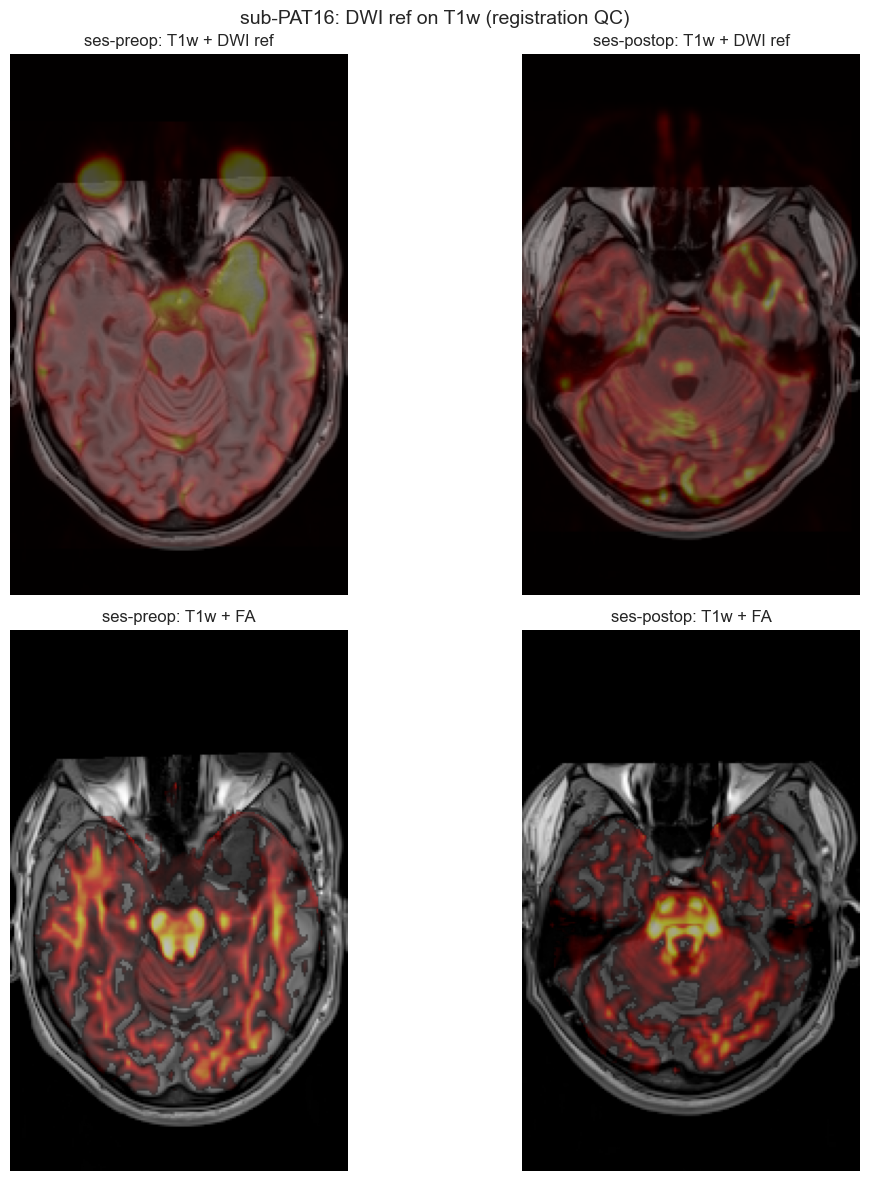

In [3]:
try:
    import nibabel as nib

    for sub in SUBJECTS:
        fig, axes = plt.subplots(2, len(SESSIONS), figsize=(6 * len(SESSIONS), 12))
        fig.suptitle(f'sub-{sub}: DWI ref on T1w (registration QC)', fontsize=14)

        for j, ses in enumerate(SESSIONS):
            sub_ses = f'sub-{sub}_ses-{ses}'
            t1w_path = FMRIPREP_DIR / f'sub-{sub}' / f'ses-{ses}' / 'anat' / f'{sub_ses}_desc-preproc_T1w.nii.gz'
            dwiref_path = REG_DIR / f'sub-{sub}' / f'ses-{ses}' / 'transforms' / 'dwiref_in_T1w.nii.gz'
            fa_path = REG_DIR / f'sub-{sub}' / f'ses-{ses}' / 'fa_space-T1w.nii.gz'

            # Row 1: T1w + DWI ref overlay
            ax1 = axes[0][j] if len(SESSIONS) > 1 else axes[0]
            if t1w_path.exists() and dwiref_path.exists():
                t1w = np.asarray(nib.load(str(t1w_path)).dataobj)
                dwi = np.asarray(nib.load(str(dwiref_path)).dataobj)
                mid = t1w.shape[2] // 2
                ax1.imshow(np.rot90(t1w[:, :, mid]), cmap='gray')
                if dwi.shape == t1w.shape:
                    ax1.imshow(np.rot90(dwi[:, :, mid]), cmap='hot', alpha=0.3)
                ax1.set_title(f'ses-{ses}: T1w + DWI ref')
            else:
                ax1.text(0.5, 0.5, 'Not available', ha='center', va='center',
                         transform=ax1.transAxes)
                ax1.set_title(f'ses-{ses}')
            ax1.axis('off')

            # Row 2: T1w + FA overlay
            ax2 = axes[1][j] if len(SESSIONS) > 1 else axes[1]
            if t1w_path.exists() and fa_path.exists():
                t1w = np.asarray(nib.load(str(t1w_path)).dataobj)
                fa = np.asarray(nib.load(str(fa_path)).dataobj)
                mid = t1w.shape[2] // 2
                ax2.imshow(np.rot90(t1w[:, :, mid]), cmap='gray')
                if fa.shape == t1w.shape:
                    fa_masked = np.ma.masked_where(fa[:, :, mid] < 0.1, fa[:, :, mid])
                    ax2.imshow(np.rot90(fa_masked), cmap='hot', alpha=0.5)
                ax2.set_title(f'ses-{ses}: T1w + FA')
            else:
                ax2.text(0.5, 0.5, 'Not available', ha='center', va='center',
                         transform=ax2.transAxes)
                ax2.set_title(f'ses-{ses}')
            ax2.axis('off')

        plt.tight_layout()
        plt.show()

except Exception as e:
    print(f'Registration QC not available: {e}')

## 3. Transform Parameters

The ACPC-to-T1w transform should be close to identity (small rotation/translation).

In [4]:
for sub in SUBJECTS:
    print(f'\n=== sub-{sub} ===')
    for ses in SESSIONS:
        mat_path = REG_DIR / f'sub-{sub}' / f'ses-{ses}' / 'transforms' / 'acpc_to_t1w_flirt.mat'
        if mat_path.exists():
            mat = np.loadtxt(str(mat_path))
            print(f'  ses-{ses}: FLIRT matrix (4x4):')
            for row in mat:
                print(f'    [{" ".join(f"{v:>10.6f}" for v in row)}]')
            # Extract translation and rotation magnitude
            trans = mat[:3, 3]
            rot_mat = mat[:3, :3]
            # Rotation angle from trace: cos(theta) = (trace(R) - 1) / 2
            trace = np.trace(rot_mat)
            cos_theta = np.clip((trace - 1) / 2, -1, 1)
            angle_deg = np.degrees(np.arccos(cos_theta))
            trans_mm = np.linalg.norm(trans)
            print(f'    Translation: {trans_mm:.2f} mm')
            print(f'    Rotation: {angle_deg:.2f} degrees')
        else:
            print(f'  ses-{ses}: not available')


=== sub-PAT16 ===
  ses-preop: FLIRT matrix (4x4):
    [ -0.999848  -0.000828  -0.017435 160.898711]
    [  0.004988  -0.970782  -0.239913 232.212449]
    [ -0.016727  -0.239964   0.970638  94.130731]
    [  0.000000   0.000000   0.000000   1.000000]
    Translation: 297.78 mm
    Rotation: 179.83 degrees
  ses-postop: FLIRT matrix (4x4):
    [ -0.999999   0.000000  -0.001016 163.414822]
    [  0.000361  -0.934559  -0.355808 243.749279]
    [ -0.000950  -0.355808   0.934559 115.639014]
    [  0.000000   0.000000   0.000000   1.000000]
    Translation: 315.42 mm
    Rotation: 179.99 degrees
